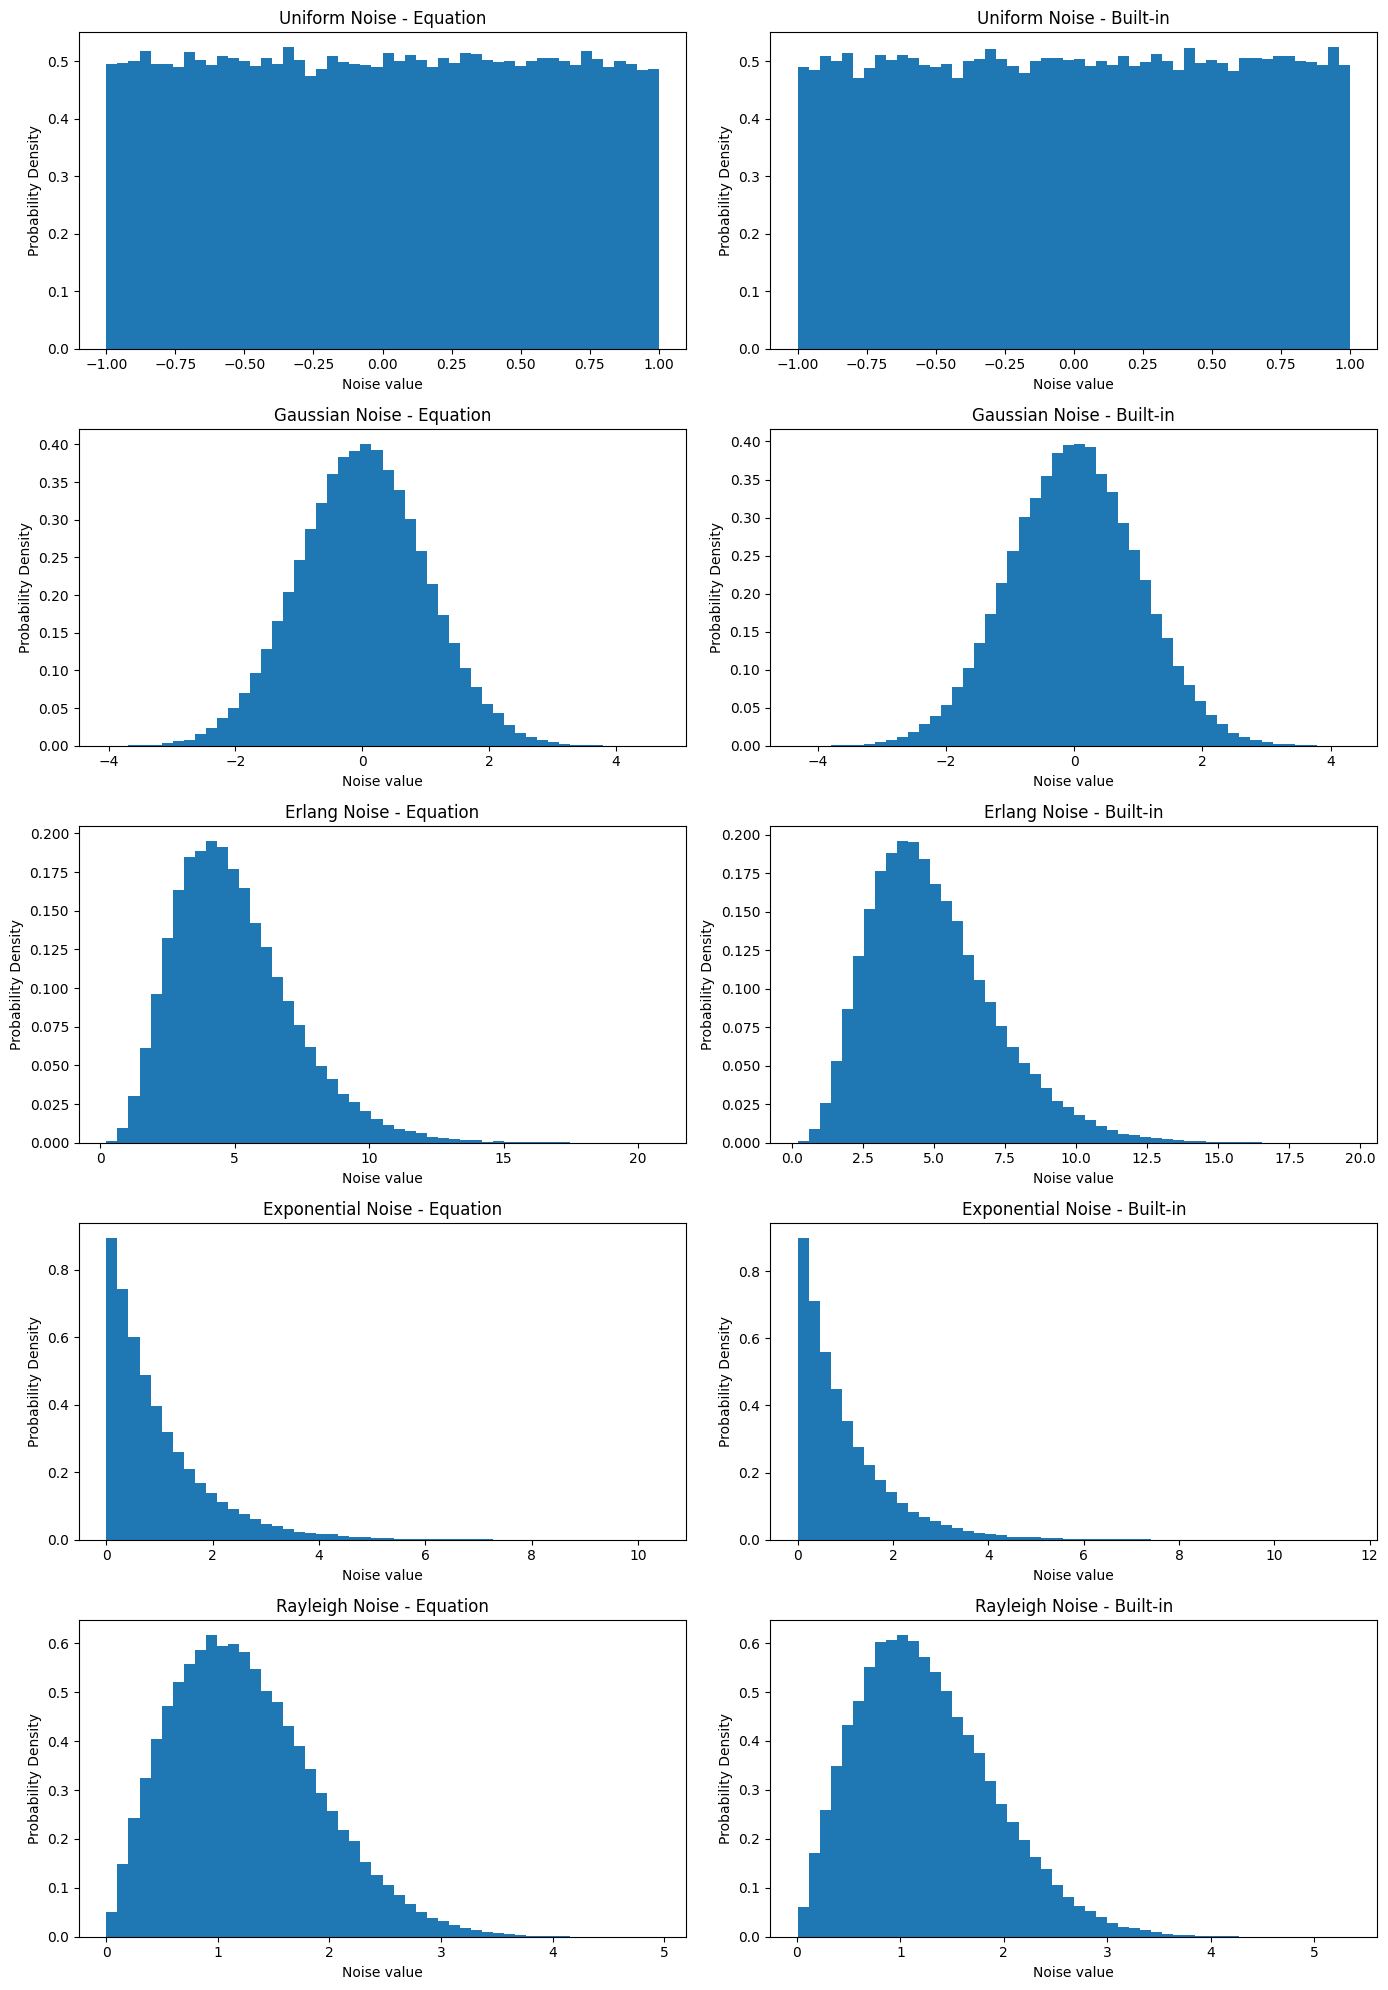

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform, norm, expon, gamma, rayleigh

# Number of noise samples
N = 100000

np.random.seed(42)

# ==========================================================
# 1. UNIFORM NOISE
# ==========================================================

# PDF:
# p(z) = 1/(b-a),  a <= z <= b
#
# Inverse transformation:
# z = a + (b-a)U

a = -1
b = 1

U = np.random.rand(N)

uniform_noise = a + (b - a) * U

# Built-in Uniform distribution
uniform_builtin = uniform.rvs(loc=a, scale=(b-a), size=N)


# ==========================================================
# 2. GAUSSIAN NOISE
# ==========================================================

# Gaussian PDF:
#
# p(z) = 1/(sqrt(2*pi)*sigma)
#        exp(-(z-mu)^2/(2*sigma^2))
#
# Box-Muller equation:
#
# Z = sqrt(-2 ln(U1)) cos(2*pi*U2)

mu = 0
sigma = 1

U1 = np.random.rand(N)
U2 = np.random.rand(N)

gaussian_noise = (
    mu + sigma *
    np.sqrt(-2 * np.log(U1)) *
    np.cos(2 * np.pi * U2)
)

# Built-in Gaussian distribution
gaussian_builtin = norm.rvs(loc=mu, scale=sigma, size=N)


# ==========================================================
# 3. ERLANG NOISE
# ==========================================================

# Erlang distribution is a Gamma distribution
# with integer shape parameter k.
#
# It can be generated as the sum of k exponential
# random variables.
#
# X = X1 + X2 + ... + Xk

k = 5
rate = 1

erlang_noise = np.zeros(N)

for i in range(k):
    U = np.random.rand(N)

    # Exponential inverse transformation
    exponential_sample = -np.log(U) / rate

    erlang_noise += exponential_sample

# Built-in Erlang/Gamma distribution
erlang_builtin = gamma.rvs(
    a=k,
    scale=1/rate,
    size=N
)


# ==========================================================
# 4. EXPONENTIAL NOISE
# ==========================================================

# Exponential PDF:
#
# p(z) = lambda * exp(-lambda*z), z >= 0
#
# Inverse transformation:
#
# z = -ln(1-U)/lambda

lam = 1

U = np.random.rand(N)

exponential_noise = -np.log(1 - U) / lam

# Built-in Exponential distribution
exponential_builtin = expon.rvs(
    scale=1/lam,
    size=N
)


# ==========================================================
# 5. RAYLEIGH NOISE
# ==========================================================

# Rayleigh PDF:
#
# p(z) = (z/beta^2) exp(-z^2/(2*beta^2)), z >= 0
#
# Inverse transformation:
#
# z = beta * sqrt(-2 ln(1-U))

beta = 1

U = np.random.rand(N)

rayleigh_noise = beta * np.sqrt(
    -2 * np.log(1 - U)
)

# Built-in Rayleigh distribution
rayleigh_builtin = rayleigh.rvs(
    scale=beta,
    size=N
)


# ==========================================================
# DISPLAY HISTOGRAMS
# ==========================================================

fig, axes = plt.subplots(5, 2, figsize=(14, 20))

# Uniform
axes[0, 0].hist(uniform_noise, bins=50, density=True)
axes[0, 0].set_title("Uniform Noise - Equation")
axes[0, 0].set_xlabel("Noise value")
axes[0, 0].set_ylabel("Probability Density")

axes[0, 1].hist(uniform_builtin, bins=50, density=True)
axes[0, 1].set_title("Uniform Noise - Built-in")
axes[0, 1].set_xlabel("Noise value")
axes[0, 1].set_ylabel("Probability Density")


# Gaussian
axes[1, 0].hist(gaussian_noise, bins=50, density=True)
axes[1, 0].set_title("Gaussian Noise - Equation")
axes[1, 0].set_xlabel("Noise value")
axes[1, 0].set_ylabel("Probability Density")

axes[1, 1].hist(gaussian_builtin, bins=50, density=True)
axes[1, 1].set_title("Gaussian Noise - Built-in")
axes[1, 1].set_xlabel("Noise value")
axes[1, 1].set_ylabel("Probability Density")


# Erlang
axes[2, 0].hist(erlang_noise, bins=50, density=True)
axes[2, 0].set_title("Erlang Noise - Equation")
axes[2, 0].set_xlabel("Noise value")
axes[2, 0].set_ylabel("Probability Density")

axes[2, 1].hist(erlang_builtin, bins=50, density=True)
axes[2, 1].set_title("Erlang Noise - Built-in")
axes[2, 1].set_xlabel("Noise value")
axes[2, 1].set_ylabel("Probability Density")


# Exponential
axes[3, 0].hist(exponential_noise, bins=50, density=True)
axes[3, 0].set_title("Exponential Noise - Equation")
axes[3, 0].set_xlabel("Noise value")
axes[3, 0].set_ylabel("Probability Density")

axes[3, 1].hist(exponential_builtin, bins=50, density=True)
axes[3, 1].set_title("Exponential Noise - Built-in")
axes[3, 1].set_xlabel("Noise value")
axes[3, 1].set_ylabel("Probability Density")


# Rayleigh
axes[4, 0].hist(rayleigh_noise, bins=50, density=True)
axes[4, 0].set_title("Rayleigh Noise - Equation")
axes[4, 0].set_xlabel("Noise value")
axes[4, 0].set_ylabel("Probability Density")

axes[4, 1].hist(rayleigh_builtin, bins=50, density=True)
axes[4, 1].set_title("Rayleigh Noise - Built-in")
axes[4, 1].set_xlabel("Noise value")
axes[4, 1].set_ylabel("Probability Density")


plt.tight_layout()
plt.show()